In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Cargar datasets 
ruta_clientes = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Clientes.csv'
ruta_categorias = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Categorias.csv'
ruta_detalles_de_pedidos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Detalles de Pedidos.csv'
ruta_empleados = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Empleados.csv'
ruta_equipos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Equipos.csv'
ruta_estaciones = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Estaciones.csv'
ruta_mantenimientos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Mantenimientos.csv'
ruta_pedidos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Pedidos.csv'
ruta_productos = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Productos.csv'
ruta_proveedores = r'C:\Users\germa\OneDrive\Documentos\2. Data Analytics\Fundacion YPF\proyecto_ypf\data\raw\Proveedores.csv'


### Clientes

In [11]:
df_clientes = pd.read_csv(ruta_clientes, sep=';')

In [ ]:
# VISTA GENERAL
print(f"Dimensiones: {df_clientes.shape}")
df_clientes.head()

Dimensiones: (91, 11)


,Id. de cliente,Nombre de compañía,Nombre del contacto,Cargo del contacto,Dirección,Ciudad,Región,Código postal,País,Teléfono,Fax
0,PEBER,Petrolera Berlín,Maria Anders,Gerente de Estación de Servicio,Obere Str. 57,Berlín,NaN,12209,Alemania,030-0074321,030-0076545
1,DICOM,Distribuidora de Combustibles México D.F.,Ana Trujillo,Jefe de Operaciones,Avda. de la Constitución 2222,México D.F.,NaN,05021,México,(5) 555-4729,(5) 555-3745
2,ESSER,Estación de Servicio México D.F.,Antonio Moreno,Supervisor de Planta,Mataderos 2312,México D.F.,NaN,05023,México,(5) 555-3932,NaN
3,GALON,GasNorte Londres,Thomas Hardy,Coordinador de Logística,120 Hanover Sq.,Londres,NaN,WA1 1DP,Reino Unido,(71) 555-7788,(71) 555-6750
4,TECOM,Terminal de Combustibles Luleå,Christina Berglund,Gerente de Compras,Berguvsvägen 8,Luleå,NaN,S-958 22,Suecia,0921-12 34 65,0921-12 34 67


In [ ]:
# ESTRUCTURA Y TIPOS DE DATOS
df_clientes.info()
print(df_clientes.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91 entries, 0 to 90
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id. de cliente       91 non-null     object
 1   Nombre de compañía   91 non-null     object
 2   Nombre del contacto  91 non-null     object
 3   Cargo del contacto   91 non-null     object
 4   Dirección            91 non-null     object
 5   Ciudad               91 non-null     object
 6   Región               31 non-null     object
 7   Código postal        90 non-null     object
 8   País                 91 non-null     object
 9   Teléfono             91 non-null     object
 10  Fax                  69 non-null     object
dtypes: object(11)
memory usage: 7.9+ KB
object    11
Name: count, dtype: int64


In [ ]:
# VALORES NULOS
nulos = df_clientes.isnull().sum()
pct_nulos = (nulos / len(df_clientes)) * 100

resumen_nulos = pd.DataFrame({'nulos': nulos, 'pct': pct_nulos.round(2)})
resumen_nulos = resumen_nulos[resumen_nulos['nulos'] > 0].sort_values('pct', ascending=False)
resumen_nulos

,nulos,pct
Región,60,65.93
Fax,22,24.18
Código postal,1,1.10


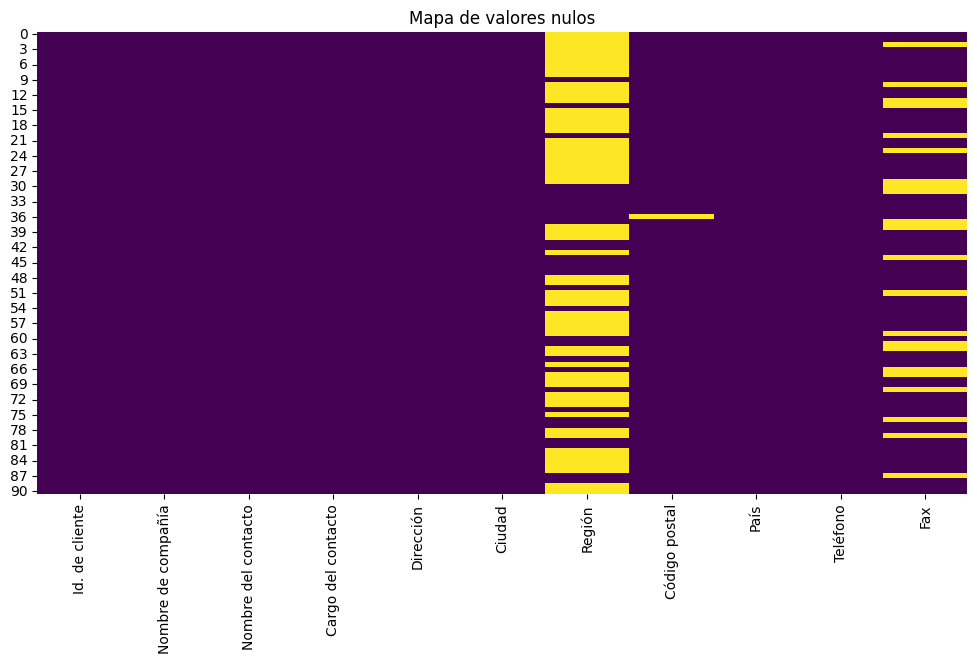

In [22]:
# Visualización de nulos
plt.figure(figsize=(12, 6))
sns.heatmap(df_clientes.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de valores nulos')
plt.show()

In [25]:
# DUPLICADOS
print(f"Filas duplicadas: {df_clientes.duplicated().sum()}")
# Si hay una columna ID/clave (ej. CUIT), revisá duplicados por esa columna puntual:
print(f"Duplicados por ID: {df_clientes.duplicated(subset=['Id. de cliente']).sum()}")

Filas duplicadas: 0
Duplicados por ID: 0


In [30]:
# ESTADÍSTICAS DESCRIPTIVAS
# Variables numéricas
#df_clientes.describe().T

# Variables categóricas
df_clientes.describe(include=['object']).T

,count,unique,top,freq
Id. de cliente,91,91,PEBER,1
Nombre de compañía,91,91,Petrolera Berlín,1
Nombre del contacto,91,91,Maria Anders,1
Cargo del contacto,91,20,Gerente de Estación de Servicio,5
Dirección,91,91,Obere Str. 57,1
Ciudad,91,70,Londres,6
Región,31,18,SP,6
Código postal,90,86,1010,3
País,91,21,Estados Unidos,13
Teléfono,91,91,030-0074321,1


In [32]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD
cat_cols = df_clientes.select_dtypes(include='object').columns

for col in cat_cols:
    n_unique = df_clientes[col].nunique()
    print(f"{col}: {n_unique} valores únicos")
    if n_unique <= 15:
        print(df_clientes[col].value_counts(normalize=True).round(3) * 100)
    print("-" * 40)

Id. de cliente: 91 valores únicos
----------------------------------------
Nombre de compañía: 91 valores únicos
----------------------------------------
Nombre del contacto: 91 valores únicos
----------------------------------------
Cargo del contacto: 20 valores únicos
----------------------------------------
Dirección: 91 valores únicos
----------------------------------------
Ciudad: 70 valores únicos
----------------------------------------
Región: 18 valores únicos
----------------------------------------
Código postal: 86 valores únicos
----------------------------------------
País: 21 valores únicos
----------------------------------------
Teléfono: 91 valores únicos
----------------------------------------
Fax: 69 valores únicos
----------------------------------------


In [34]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS
#num_cols = df_clientes.select_dtypes(include=np.number).columns

#df_clientes[num_cols].hist(figsize=(14, 10), bins=30)
#plt.tight_layout()
#plt.show()

In [36]:
# OUTLIERS
#for col in numericas:
#    plt.figure(figsize=(8, 3))
    
#    sns.boxplot(
#        data=df_clientes,
#        x=col
#    )
    
#    plt.title(f'Boxplot de {col}')
#    plt.show()

###

### Categorías

In [8]:
df_categorias = pd.read_csv(ruta_categorias, sep=';', encoding='latin1')

In [9]:
# VISTA GENERAL
print(f"Dimensiones: {df_categorias.shape}")
df_categorias.head()

Dimensiones: (8, 3)


,IdCategoria,NombreCategoria,Imagen
0,1,Combustibles Líquidos,NaN
1,2,Lubricantes,NaN
2,3,GNC,NaN
3,4,Aditivos y Químicos,NaN
4,5,Repuestos,NaN


In [10]:
# ESTRUCTURA Y TIPOS DE DATOS
df_categorias.info()
print(df_categorias.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   IdCategoria      8 non-null      int64  
 1   NombreCategoria  8 non-null      object 
 2   Imagen           0 non-null      float64
dtypes: float64(1), int64(1), object(1)
memory usage: 324.0+ bytes
int64      1
object     1
float64    1
Name: count, dtype: int64


In [12]:
# VALORES NULOS

nulos = df_categorias.isnull().sum()

pct_nulos = (nulos / len(df_categorias)) * 100

resumen_nulos = pd.DataFrame({
    'nulos': nulos,
    'pct': pct_nulos.round(2)
})

resumen_nulos = (
    resumen_nulos[
        resumen_nulos['nulos'] > 0
    ]
    .sort_values('pct', ascending=False)
)

resumen_nulos

,nulos,pct
Imagen,8,100.0


In [13]:
# DUPLICADOS

print(f"Filas duplicadas: {df_categorias.duplicated().sum()}")

Filas duplicadas: 0


In [15]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_categorias.duplicated(subset=['IdCategoria']).sum()}"
)

Duplicados por ID: 0


In [16]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES CATEGÓRICAS

df_categorias.describe(include=['object']).T

,count,unique,top,freq
NombreCategoria,8,8,Combustibles Líquidos,1


In [17]:
# VARIABLES CATEGÓRICAS - CARDINALIDAD

cat_cols = df_categorias.select_dtypes(include='object').columns

for col in cat_cols:

    n_unique = df_categorias[col].nunique()

    print(f"{col}: {n_unique} valores únicos")

    if n_unique <= 15:
        print(
            df_categorias[col]
            .value_counts(normalize=True, dropna=False)
            .round(3) * 100
        )

    print("-" * 40)

NombreCategoria: 8 valores únicos
NombreCategoria
Combustibles Líquidos    12.5
Lubricantes              12.5
GNC                      12.5
Aditivos y Químicos      12.5
Repuestos                12.5
Accesorios               12.5
Seguridad Industrial     12.5
Servicios Técnicos       12.5
Name: proportion, dtype: float64
----------------------------------------


### Detalles de Pedidos

In [18]:
df_detalles_de_pedidos = pd.read_csv(ruta_detalles_de_pedidos, sep=';', encoding='latin1') 

In [19]:
# VISTA GENERAL

print(f"Dimensiones: {df_detalles_de_pedidos.shape}")

df_detalles_de_pedidos.head()

Dimensiones: (5937, 7)


,Iddepedido,Producto,Cantidad,Descuento,Total,CostosDirectos,CostosIndirectos
0,8787,5,12,0.20,219.82,54.95,39.57
1,8788,7,15,0.00,482.63,120.66,86.87
2,8789,56,2,0.00,81.51,20.38,14.67
3,8790,16,60,0.25,842.18,210.55,151.59
4,8791,24,28,0.00,135.14,33.78,24.32


In [20]:
# ESTRUCTURA Y TIPOS DE DATOS

df_detalles_de_pedidos.info()

print("\nCantidad de columnas por tipo de dato:")
print(df_detalles_de_pedidos.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Iddepedido        5937 non-null   int64  
 1   Producto          5937 non-null   int64  
 2   Cantidad          5937 non-null   int64  
 3   Descuento         5937 non-null   float64
 4   Total             5937 non-null   float64
 5   CostosDirectos    5937 non-null   float64
 6   CostosIndirectos  5937 non-null   float64
dtypes: float64(4), int64(3)
memory usage: 324.8 KB

Cantidad de columnas por tipo de dato:
float64    4
int64      3
Name: count, dtype: int64


In [21]:
# DUPLICADOS

print(f"Filas duplicadas: {df_detalles_de_pedidos.duplicated().sum()}")

Filas duplicadas: 0


In [ ]:
# DUPLICADOS POR CLAVE / ID
# Reemplazar 'COLUMNA_ID' por la clave correspondiente

print(
    f"Duplicados por ID: "
    f"{df_detalles_de_pedidos.duplicated(subset=['Iddepedido']).sum()}"
)

Duplicados por ID: 1325


No existen registros completamente duplicados en la tabla Detalles de Pedidos. 
Sin embargo, Iddepedido se repite en 1325 registros,
lo cual puede ser esperable debido a que un mismo pedido
 puede contener múltiples líneas de detalle.

In [24]:
# ESTADÍSTICAS DESCRIPTIVAS
# VARIABLES NUMÉRICAS

num_cols = df_detalles_de_pedidos.select_dtypes(include=np.number).columns

df_detalles_de_pedidos[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Iddepedido,5937.0,10995.400034,1192.947052,8787.00,10255.00,10826.00,11914.00,13398.00
Producto,5937.0,28.321880,19.038627,1.00,11.00,26.00,44.00,62.00
Cantidad,5937.0,23.856493,19.168346,1.00,10.00,20.00,30.00,130.00
Descuento,5937.0,0.055779,0.082909,0.00,0.00,0.00,0.10,0.25
Total,5937.0,414.718961,731.006022,1.85,84.41,209.88,479.12,15130.17
CostosDirectos,5937.0,103.680072,182.751517,0.46,21.10,52.47,119.78,3782.54
CostosIndirectos,5937.0,74.649424,131.581163,0.33,15.19,37.78,86.24,2723.43


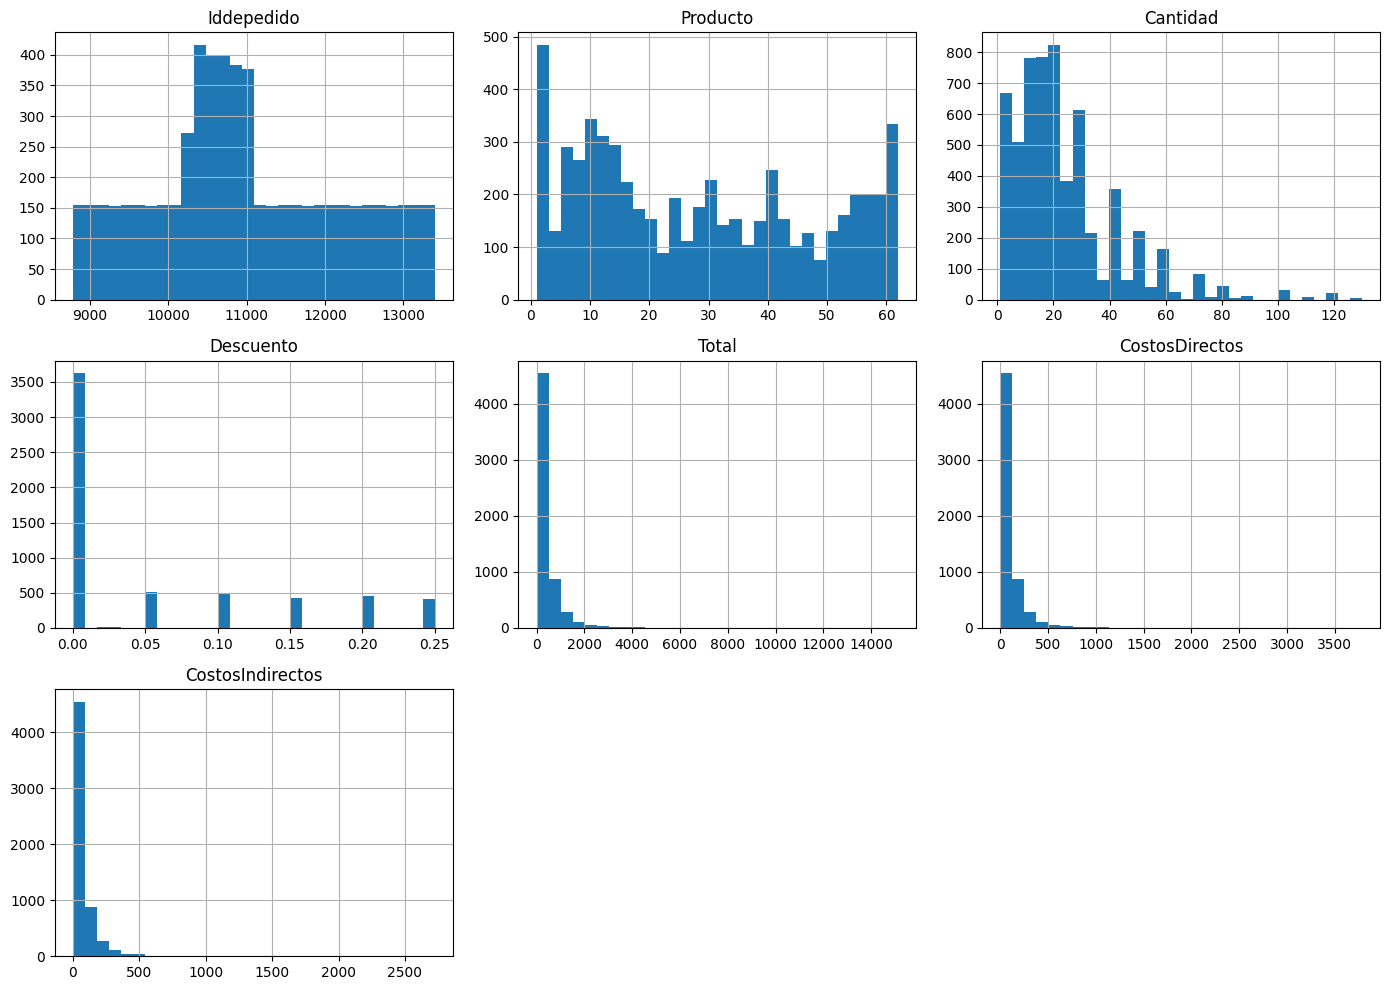

In [25]:
# DISTRIBUCIÓN DE VARIABLES NUMÉRICAS

df_detalles_de_pedidos[num_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

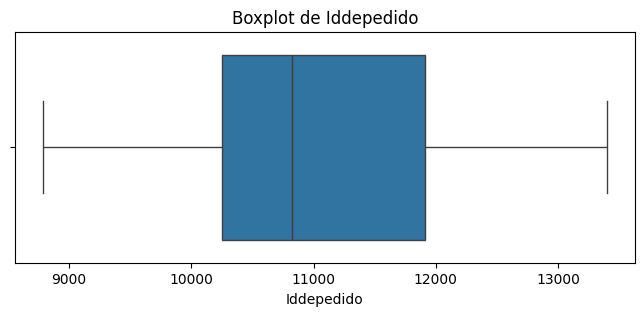

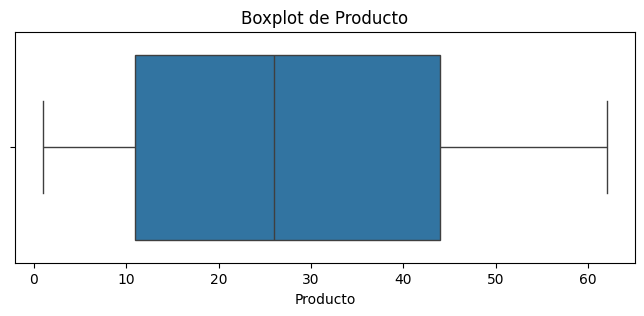

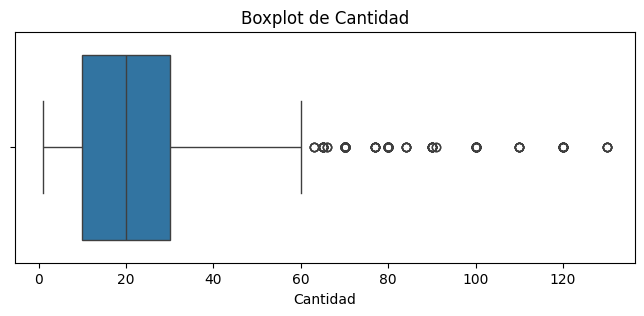

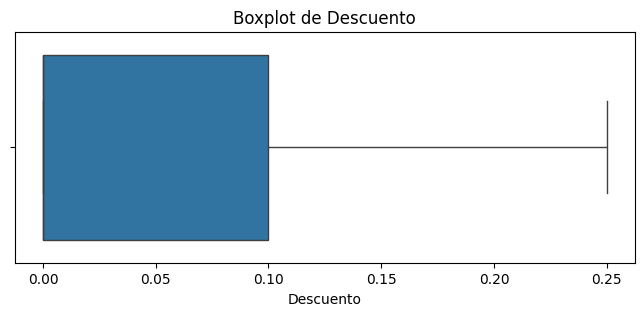

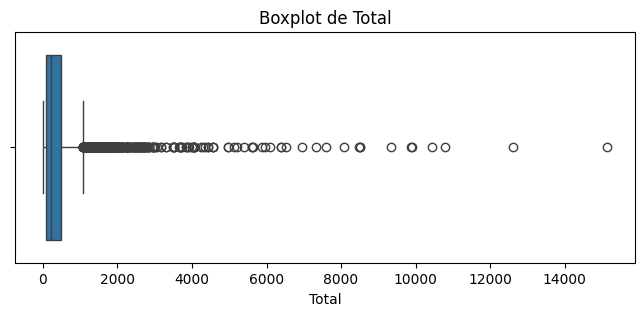

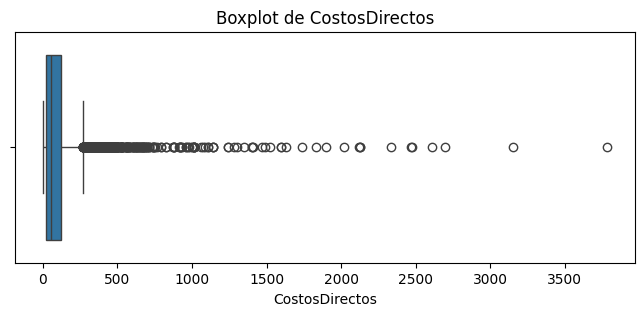

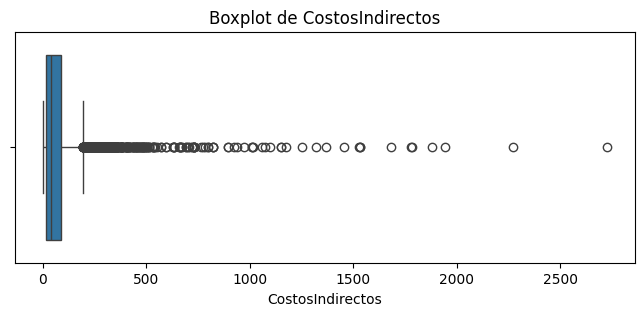

In [27]:
# OUTLIERS

for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(
        data=df_detalles_de_pedidos,
        x=col
    )

    plt.title(f'Boxplot de {col}')
    plt.show()